<a href="https://colab.research.google.com/github/sardorbekmuminov/transfer-learning-project/blob/main/Dars62_Flowers_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dars 62 topshirig'i: Gullarni tanish (Flowers Recognition)
Transfer learning: ImageNet'da o'qitilgan **ResNet18** (timm) ni 5 xil gulga o'rgatamiz.

- Ma'lumot: Kaggle `alxmamaev/flowers-recognition` (daisy, dandelion, rose, sunflower, tulip)
- Usullar: noldan, feature extraction, fine-tuning (darsdagi kabi)
- Natija: val accuracy, F1, confusion matrix, yangi rasmlarda sinov

**Colab: Runtime → Change runtime type → T4 GPU**

In [1]:
!pip install -q timm kagglehub

In [2]:
import random, time, zipfile, numpy as np, torch, torch.nn as nn
import torch.nn.functional as F, timm
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"   # torch.device ni qayta yozmaymiz
print("device:", device)

IMG = 128          # darsdagidek. GPU bo'lsa 224 qilib ko'rishingiz mumkin
random.seed(0)
torch.manual_seed(0)

device: cuda


## 1. Ma'lumotni yuklash
`kagglehub` ochiq datasetni akkauntsiz yuklaydi. Agar xato bersa: datasetni Kaggle saytidan zip qilib yuklab oling, Colab'ga yuklang va
`zipfile.ZipFile("flowers-recognition.zip").extractall("flowers_data")` qilib, `path = "flowers_data"` deb yozing.

In [3]:
import kagglehub
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print(path)

# klass papkalari (daisy, rose, ...) joylashgan papkani o'zimiz topamiz
root = next(p for p in Path(path).rglob("daisy") if p.is_dir()).parent
classes = sorted(p.name for p in root.iterdir() if p.is_dir())
EXT = {".jpg", ".jpeg", ".png"}

def class_files(name):
    return sorted(f for f in (root / name).iterdir() if f.suffix.lower() in EXT)

print(root)
for c in classes:
    print(c, len(class_files(c)))

Using Colab cache for faster access to the 'flowers-recognition' dataset.
/kaggle/input/flowers-recognition
/kaggle/input/flowers-recognition/flowers
daisy 764
dandelion 1052
rose 784
sunflower 733
tulip 984


## 2. Train / validation ajratish (har klassdan 80% / 20%) va tensorga o'tkazish

In [4]:
train_f, val_f, ytr_l, yte_l = [], [], [], []
for c, name in enumerate(classes):
    files = class_files(name)
    random.shuffle(files)
    k = int(len(files) * 0.8)
    train_f += files[:k];  ytr_l += [c] * k
    val_f   += files[k:];  yte_l += [c] * (len(files) - k)

def load(files):
    X = [np.asarray(Image.open(f).convert("RGB").resize((IMG, IMG))) for f in files]
    return torch.tensor(np.stack(X), device=device).permute(0, 3, 1, 2)

Xtr, Xte = load(train_f), load(val_f)
ytr = torch.tensor(ytr_l, device=device)
yte = torch.tensor(yte_l, device=device)
print(Xtr.shape, Xte.shape)

torch.Size([3452, 3, 128, 128]) torch.Size([865, 3, 128, 128])


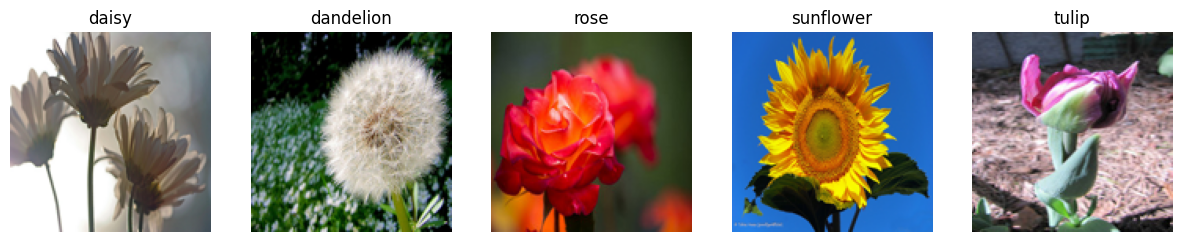

In [5]:
# Har klassdan bitta rasm
fig, ax = plt.subplots(1, len(classes), figsize=(3 * len(classes), 3))
for c, a in enumerate(ax):
    i = (ytr == c).nonzero()[0].item()
    a.imshow(Xtr[i].cpu().permute(1, 2, 0)); a.set_title(classes[c]); a.axis("off")
plt.show()

## 3. Darsdagi funksiyalar: prep, acc, train

In [6]:
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
prep = lambda xb: (xb.float() / 255 - mean) / std

def predict_all(m, X):
    m.eval()
    with torch.no_grad():
        return torch.cat([m(prep(X[i:i + 100])) for i in range(0, len(X), 100)]).argmax(1)

def acc(m, X, y):
    return (predict_all(m, X) == y).float().mean().item()

def train(m, params, epochs=5, lr=1e-3, bs=32):
    t0 = time.time()
    opt = torch.optim.Adam(params, lr=lr)
    accs = []
    for e in range(epochs):
        m.train()
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(m(prep(Xtr[idx])), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        accs.append(acc(m, Xte, yte))
        print(f"epoch {e + 1}/{epochs} | val acc {accs[-1]:.3f} | {time.time() - t0:.0f}s")
    return accs

NC = len(classes)
res = {}

## 4. Uch usul

### 1-usul: noldan o'qitish (pretrained=False)

In [7]:
# Noldan o'qitish GPU'da ~1 daqiqa, CPU'da 15+ daqiqa. CPU bo'lsa o'tkazib yuboramiz.
RUN_SCRATCH = device == "cuda"      # xohlasangiz True/False qilib o'zingiz o'zgartiring
if RUN_SCRATCH:
    torch.manual_seed(0)
    scratch = timm.create_model("resnet18", pretrained=False, num_classes=NC).to(device)
    res["noldan"] = train(scratch, scratch.parameters())
    print([round(a, 2) for a in res["noldan"]])
else:
    print("CPU: noldan o'qitish o'tkazib yuborildi. Runtime -> Change runtime type -> T4 GPU")

epoch 1/5 | val acc 0.575 | 11s
epoch 2/5 | val acc 0.583 | 19s
epoch 3/5 | val acc 0.660 | 26s
epoch 4/5 | val acc 0.622 | 34s
epoch 5/5 | val acc 0.698 | 41s
[0.57, 0.58, 0.66, 0.62, 0.7]


### 2-usul: feature extraction (backbone qotirilgan, faqat Linear o'qiladi)

In [8]:
bb = timm.create_model("resnet18", pretrained=True, num_classes=0).to(device).eval()

def feats(X):
    with torch.no_grad():
        return torch.cat([bb(prep(X[i:i + 100])) for i in range(0, len(X), 100)])

Ftr, Fte = feats(Xtr), feats(Xte)
print(Ftr.shape)

torch.manual_seed(0)
head = nn.Linear(512, NC).to(device)
opt = torch.optim.Adam(head.parameters(), lr=1e-3)
accs = []
for e in range(50):
    perm = torch.randperm(len(Ftr), device=device)
    for i in range(0, len(Ftr), 32):
        idx = perm[i:i + 32]
        loss = F.cross_entropy(head(Ftr[idx]), ytr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    accs.append((head(Fte).argmax(1) == yte).float().mean().item())
res["feature extraction"] = accs
print(round(accs[-1], 3))

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([3452, 512])
0.876


### 3-usul: fine-tuning (butun model, lr = 3e-4)

In [9]:
torch.manual_seed(0)
model = timm.create_model("resnet18", pretrained=True, num_classes=NC).to(device)
res["fine-tuning"] = train(model, model.parameters(), lr=3e-4)
print([round(a, 2) for a in res["fine-tuning"]])

epoch 1/5 | val acc 0.849 | 8s
epoch 2/5 | val acc 0.880 | 15s
epoch 3/5 | val acc 0.883 | 23s
epoch 4/5 | val acc 0.887 | 31s
epoch 5/5 | val acc 0.891 | 38s
[0.85, 0.88, 0.88, 0.89, 0.89]


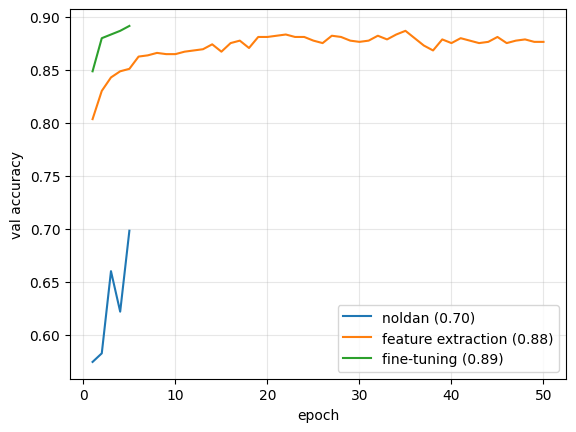

In [10]:
# Uch usulni solishtirish
for k, v in res.items():
    plt.plot(range(1, len(v) + 1), v, label=f"{k} ({v[-1]:.2f})")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 5. Darsdagi topshiriq: fine-tuning 10 epoch, lr = 1e-4 / 3e-4 / 1e-3
Eng yaxshisini `best_model` ga saqlaymiz.

epoch 1/10 | val acc 0.692 | 8s
epoch 2/10 | val acc 0.803 | 16s
epoch 3/10 | val acc 0.842 | 23s
epoch 4/10 | val acc 0.859 | 31s
epoch 5/10 | val acc 0.873 | 39s
epoch 6/10 | val acc 0.881 | 47s
epoch 7/10 | val acc 0.886 | 55s
epoch 8/10 | val acc 0.887 | 63s
epoch 9/10 | val acc 0.891 | 71s
epoch 10/10 | val acc 0.889 | 79s
lr=0.0001: [0.69, 0.8, 0.84, 0.86, 0.87, 0.88, 0.89, 0.89, 0.89, 0.89]
epoch 1/10 | val acc 0.849 | 8s
epoch 2/10 | val acc 0.872 | 16s
epoch 3/10 | val acc 0.886 | 24s
epoch 4/10 | val acc 0.891 | 32s
epoch 5/10 | val acc 0.895 | 40s
epoch 6/10 | val acc 0.896 | 48s
epoch 7/10 | val acc 0.904 | 56s
epoch 8/10 | val acc 0.899 | 64s
epoch 9/10 | val acc 0.902 | 73s
epoch 10/10 | val acc 0.896 | 81s
lr=0.0003: [0.85, 0.87, 0.89, 0.89, 0.89, 0.9, 0.9, 0.9, 0.9, 0.9]
epoch 1/10 | val acc 0.861 | 8s
epoch 2/10 | val acc 0.879 | 16s
epoch 3/10 | val acc 0.889 | 24s
epoch 4/10 | val acc 0.880 | 33s
epoch 5/10 | val acc 0.879 | 41s
epoch 6/10 | val acc 0.875 | 49s
epoch

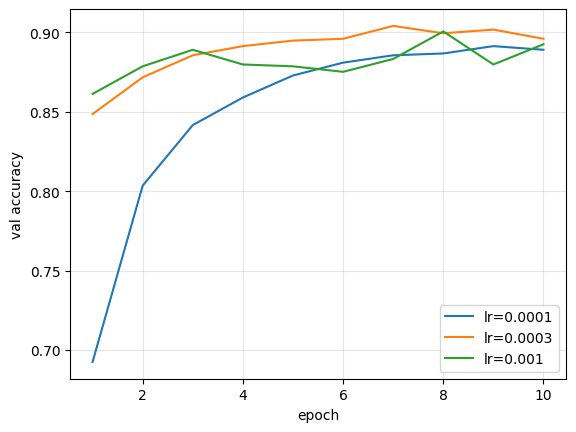

In [11]:
exp, best_acc, best_model, best_lr = {}, 0, None, None
for lr in [1e-4, 3e-4, 1e-3]:
    torch.manual_seed(0)
    m = timm.create_model("resnet18", pretrained=True, num_classes=NC).to(device)
    a = train(m, m.parameters(), epochs=10, lr=lr)
    exp[lr] = a
    print(f"lr={lr}: {[round(x, 2) for x in a]}")
    if a[-1] > best_acc:
        best_acc, best_model, best_lr = a[-1], m, lr

print("Eng yaxshi lr:", best_lr, "| val acc:", round(best_acc, 4))
for lr, a in exp.items():
    plt.plot(range(1, 11), a, label=f"lr={lr}")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 6. Natija: accuracy, F1, confusion matrix

Validation accuracy: 0.896
F1 (macro): 0.8967
              precision    recall  f1-score   support

       daisy       0.90      0.91      0.91       153
   dandelion       0.94      0.91      0.92       211
        rose       0.87      0.89      0.88       157
   sunflower       0.94      0.89      0.92       147
       tulip       0.84      0.89      0.86       197

    accuracy                           0.90       865
   macro avg       0.90      0.90      0.90       865
weighted avg       0.90      0.90      0.90       865



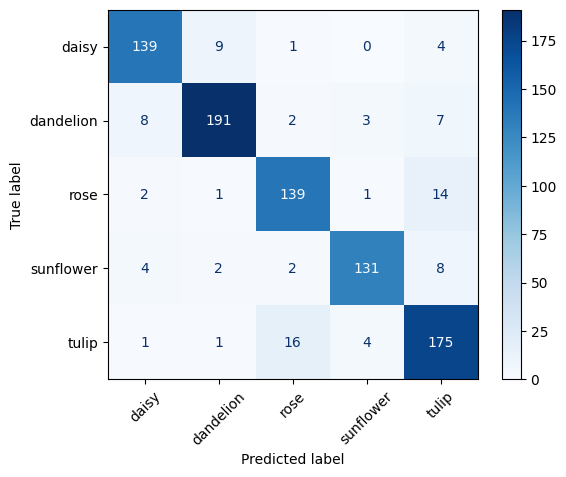

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

y_pred = predict_all(best_model, Xte).cpu().numpy()
y_true = yte.cpu().numpy()

print("Validation accuracy:", round((y_pred == y_true).mean(), 4))
print("F1 (macro):", round(f1_score(y_true, y_pred, average="macro"), 4))
print(classification_report(y_true, y_pred, target_names=classes))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap="Blues", xticks_rotation=45)
plt.show()

In [13]:
# app.py shu fayldan foydalanadi
torch.save({"state_dict": best_model.state_dict(), "classes": classes, "img": IMG}, "flowers.pt")

## 7. Yangi 2-3 ta rasm bilan sinash
Internetdan datasetda **yo'q** gul rasmlarini yuklab oling (jpg) va quyidagi katakda yuklang.

Saving images_2.jpeg to images_2.jpeg


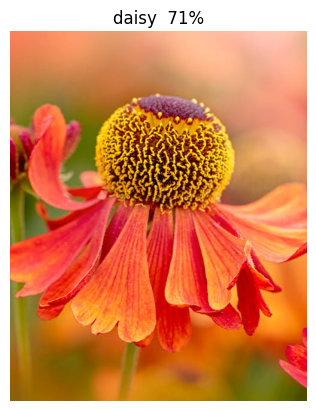

In [14]:
from google.colab import files
up = files.upload()

best_model.eval()
for name in up:
    img = Image.open(name).convert("RGB")
    x = torch.tensor(np.asarray(img.resize((IMG, IMG))), device=device).permute(2, 0, 1)[None]
    with torch.no_grad():
        p = best_model(prep(x)).softmax(1)[0]
    k = p.argmax().item()
    plt.imshow(img); plt.axis("off")
    plt.title(f"{classes[k]}  {p[k].item():.0%}"); plt.show()

## 8. Oddiy sayt (Gradio)
Rasm yuklaysiz, model gul nomini va ishonchini ko'rsatadi. Pastda `https://....gradio.live` ssilka chiqadi.

In [15]:
!pip install -q gradio

In [16]:
import gradio as gr

def predict(img):
    img = img.convert("RGB").resize((IMG, IMG))
    x = torch.tensor(np.asarray(img), device=device).permute(2, 0, 1)[None]
    best_model.eval()
    with torch.no_grad():
        p = best_model(prep(x)).softmax(1)[0].cpu()
    return {c: float(v) for c, v in zip(classes, p)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Gul rasmini yuklang"),
    outputs=gr.Label(num_top_classes=5, label="Natija"),
    title="Gullarni tanish (ResNet18, transfer learning)",
)
demo.launch(share=True)   # public ssilka beradi

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e4683935846daaf195.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Xulosa (o'zingiz to'ldiring)
- Qaysi usul eng yaxshi chiqdi va nega? (feature extraction vs fine-tuning)
- Qaysi lr eng yaxshi bo'ldi?
- Confusion matrix'da qaysi gullar adashtirildi? (masalan rose va tulip)
- Yangi rasmlarda model qanday ishladi?